*Do not delete this style setting*

In [185]:
%%html
<style>
table {float:left}
</style>

# Session 1:<br>A simple QML model in PennyLane
<table>
    <tr><td><strong>Aim:</strong></td>
        <td>To explore the process of developing a <strong>PennyLane</strong> quantum model.<br/>Watch out for modeling pits and traps!</td></tr>
    <tr><td><strong>Author:</strong></td>
        <td>Jacob L. Cybulski (<a href="https://jacobcybulski.com/" target="_blank">website</a>),
            <em>Enquanted</em></td></tr>
    <tr><td><strong>Release:</strong></td>
        <td>April 2025</td></tr>
    <tr><td><strong>Updated:</strong></td>
        <td>October 2026</td></tr>
    <tr><td><strong>Datasets:</strong></td>
        <td>Use the following two data sets (code below):<br>
            <ol><li>$y = sin(x)$</li><li>$y = sin(0.7 x+0.5\pi)$</li></ol></td></tr>
    <tr><td><strong>Tasks:</strong></td>
        <td>Time: 40 minutes (unfinished tasks go to self-directed "challenges").<br>
            All tasks listed in this table have been colour-coded across the notebook.<br>
            To make changes, you will need to hunt for the relevant section.</td></tr>
    <tr>
        <td></td>
        <td>Perform the following tasks and observe their impact on the model performance.<br>
            (Record your observations at end of this notebook):<br><ol>
            <li>Initially use <strong><em>the first dataset</em></strong> and the <strong><em>simplistic model 1</em></strong> (as provided).<br>
                Follow the instructor demonstration to step through the code and observe the results.<br>
                - run the notebook as is<br>
                - change the number of epochs to 50 (Restart Kernel and run cell-by-cell again)<br>
                - change the default.qubit to lightning.qubit (Restart Kernel and Run All Cells)</li>
            <li>Can the model performance be improved by trivial changes, such as:<br>
                - alter the range of model init values ? (reduce "high" for training)</li>
            <li>Can you improve the quantum model by changing the ansatz size, by:<br>
                (you may need to increase the number of epochs):<br>
                - using more qubits or more layers ? (those of you with big computers)<br>
                - using fewer qubits or fewer layers ? (those of you with tiny laptops)</li>
            <li>Can the model work with a single qubit and single layer ?</li>
            <li>Change the data encoding gate from RY to RX ?<br>
                - what happens and why?<br>
                - can the performance be further improved by changing the training epochs?</li>
            <li>Change entangling from basic (R with 1 param) to strong (R with 3 params).<br>
                - what is the reason for the result ?</li><br>
                <em>The tasks below will be demonstrated by your instructor.</em><br>
                <em>However, we would like you to attempt them as challenge tasks.</em><br><br>
            <li>Try the current and original model with <strong><em>the second data set</em></strong><br>
                by commenting / uncommenting code in Data Generation section<br>
                Can you improve the model performance by varying:<br>
                - the number of qubits ?<br>
                - the number of layers ?<br>
                - by increasing data range (say: -6..12) ?<br>
                - by adding more training data (say: 96) ?</li>
            <li>Can you improve the result by data reuploading, i.e. by implementing: <br>
                - <strong><em>partial reuploading:</em></strong> for all qubits within encoding block, as in <strong><em>model 2</em></strong> ?<br>
                - <strong><em>full reuploading:</em></strong> in between entangling blocks, as in <strong><em>model 3</em></strong> ?</li>
                  Suggestion: first use 'default.qubit' and diff_method='parameter-shift'<br>
                  Then: try 'lightning.qubit' and diff_method='adjoint' (hard)<br>
            <li>Reflect on this session.</li>
        </ol></td>
    </tr>
    <tr>
        <td><strong>Challenge<br>Tasks:</strong></td>
        <td>Perform the following tasks in your own time:<br/>
        <ol style="list-style-type: upper-alpha;">
            <li>Complete the unfinished tasks.</li>
            <li>Is there a way of improving the model results for <strong><em>the second data set</em></strong> ?<br>
                <em>The answer will be revealed on <strong>day 2</strong> of the workshop !</em></li>
            <li>Experiment with different optimisers and their hyper-parameters.</li>
            <li>Write your own optimiser - see example at the end of the notebook.</li></ol>
        </td>
    </tr>
    <tr><td><strong>References:</strong></td>
        <td><a href="https://pennylane.ai/qml/demos/tutorial_expressivity_fourier_series" target="_blank">
            Maria Schuld and Johannes Jakob Meyer, "Quantum models as Fourier series",<br>PennyLane, November 6, 2024.</a></td>
    </tr>
    <tr><td><strong>License:</strong></td>
        <td>This project is licensed under the 
            <a href="https://www.gnu.org/licenses/gpl-3.0.en.html" target="_blank">GNU General Public License v3</a></td></tr>
    <tr><td><strong>Changes:</strong></td>
        <td>All significant changes to this code must be listed at the bottom of this notebook</td></tr>
</table>

## Load the necessary packages
<font color="LightCoral">Task 1: Follow the instructor demonstration to step through the code.</font>

<font color="CornflowerBlue">Note that PennyLane redefines <strong><em>numpy</em></strong> -<br>
This is necessary to ensure that all mathematical operations are differentiable !<br>
We import "torch" even though it is not used directly, so that 'lightning.qubit' works properly on Linux systems.</font>

In [186]:
import time
import copy

import pennylane as qml
from pennylane import numpy as np
from matplotlib import pyplot as plt
import torch

%matplotlib inline

## Settings

<font color="LightCoral">Task 1: Follow the instructor demonstration to step through the code.</font>
- <font color="LightCoral">Change training <em>epochs</em> to <em><strong>50</strong></em> (e.g. or more).</font>

<font color="LightCoral">Task 3: Experiment with the model size.</font>
- <font color="LightCoral">Change the model <em>width</em>, i.e. the number of qubits <em><strong>n_qubits</strong></em> (e.g. try 4).</font>
- <font color="LightCoral">Change the model <em>depth</em>, i.e. the number of layers <em><strong>n_layers</strong></em> (e.g. try 1, 2 and 6).</font>

<font color="CornflowerBlue">When increasing the model size, you may also need<br>to increase the number of training <em><strong>epochs</strong></em> (e.g. use 50).</font>

<font color="LightCoral">Task 4: Experiment with the model of a single qubit and single layer.</font><br>
- <font color="LightCoral">Change <em><strong>n_qubits=1</strong></em> and <em><strong>n_layers=1</strong></em>, then observe the model training performance.</font>
- <font color="LightCoral">What happened ? What do you think is the reason for the result ?</font>

In [187]:
n_sample = 64
n_qubits = 2 #ORIGINAL 2
n_layers = 5 # 6 (fast computers) # 2 and 1 (slow computers) ORIGINAL 4
epochs = 50 # 50 (preferred) # 100 # 300 (may take hours)
seed = 2025

np.random.seed(seed)

---

## <font color="blue">Data preparation</font>

<font color="LightCoral">Task 7: Change to data set 2.<br>
Can you improve the model performance by varying (see the relevant sections):</font>
- <font color="LightCoral">the number of qubits ?</font>
- <font color="LightCoral">the number of layers ?</font>
- <font color="LightCoral">by increasing data range (say: -6..12) ?</font>
- <font color="LightCoral">by adding more training data (say: 96) ?</font>

<font color="CornflowerBlue">Data sets can be switched by commenting / uncommenting code responsible for generating X and y vectors.</font>

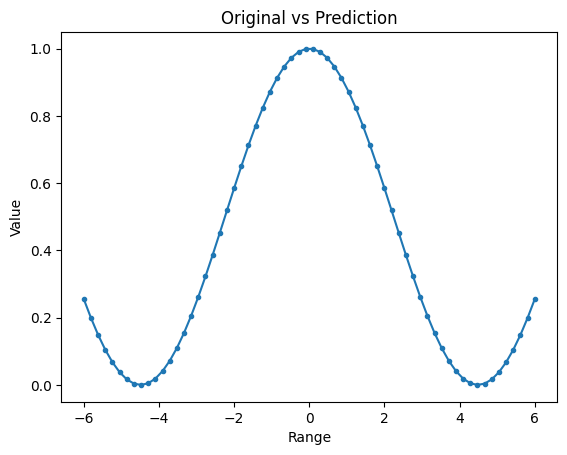

In [188]:
### Generate data set #1
#X = np.linspace(-6, 6, n_sample, requires_grad=False)
#X = X.reshape((X.shape[0], 1))
#y = np.sin(X[:,0], requires_grad=False)

### Switch to data set #2
X = np.linspace(-6, 6, n_sample, requires_grad=False)
X = X.reshape((X.shape[0], 1))
y = (np.sin(0.7*X[:,0]+0.5*np.pi, requires_grad=False)+1.0)*0.5

plt.title('Original vs Prediction')
plt.xlabel('Range')
plt.ylabel('Value')
plt.plot(X[:,0],y,'.-')
plt.show()

---

## <font color="blue">Model development</font>

## Alternative model definitions

<font color="LightCoral">Task 1: Follow the instructor demonstration to step through the code.</font>
- <font color="LightCoral">Try changing <em>device qubit</em> to <em><strong>'lightning.qubit'</strong></em> (i.e. comment/uncomment).</font>

<font color="CornflowerBlue">Your system is likely to work much faster, if not change back.</font>

In [189]:
### A range of sample models to try (select below)
#   Device based on 'default.qubit' are safer but slower
#   Device based on 'lightning.qubit' can be faster (not always)
#   Selected differential methods include 'adjoint' and 'parameter-shift' 

dev = qml.device('default.qubit', wires=n_qubits, shots=None)
#dev = qml.device('lightning.qubit', wires=n_qubits, shots=None)

### Simplistic model

<font color="LightCoral">Task 5: Change the data encoding gate from RY to RX.</font>
- <font color="LightCoral">What was the impact of this change on the model performance? Why?</font>
- <font color="LightCoral">Can the performance be further improved by changing the training epochs?</font>

<font color="LightCoral">Task 6: Change entangling from basic (R with 1 param) to strong (R with 3 params).<br>
- <font color="LightCoral">What is the reason for the result ?</font>

<font color="CornflowerBlue">Ensure the ansatz shape matches parameter initialisation!<br>
Cf. sections: "Model visualisation" and "Model initialisation".</font>

In [190]:
@qml.qnode(dev, diff_method='adjoint')
def qnn_model_1(params, x):
    
    # Data encoding
    qml.RY(x, wires=0)
    
    # Ansatz, note:
    #   basic entangling  - 1 trainable parameter / layer per qubit)
    #   strong entangling - 3 trainable parameters / layer per qubit)
    #qml.BasicEntanglerLayers(params, wires=range(n_qubits), rotation=qml.RY)
    qml.StronglyEntanglingLayers(params, wires=range(n_qubits))
    
    return qml.expval(qml.PauliZ(0))

### Data reuploading models

<font color="LightCoral">Task 8: Can you improve the result by data reuploading, i.e. by implementing:</font>
- <font color="LightCoral"><strong>partial reuploading:</strong> for all qubits within the encoding block, as in <strong><em>model 2</em></strong> ?</font>
- <font color="LightCoral"><strong>full reuploading:</strong> for all qubits and layers, in between the entangling blocks, as in <strong><em>model 3</em></strong> ?</font>

<font color="CornflowerBlue">When changing the model, make sure to assign the new model name to the variable <strong><em>qnn_model</em></strong>.<br>
See the section immediately following definitions of models <strong><em>qnn_model_2</em></strong> and <strong><em>qnn_model_3</em></strong>.</font>

In [191]:
### Partial data reuploading model
#   Notes: encoding relies on data to be reuploaded into each qubit
#          this model is to be used for the more complex dataset 2
@qml.qnode(dev, diff_method='adjoint')
def qnn_model_2(params, x):

    # Data encoding
    for q in range(n_qubits):
        qml.RY(x, wires=q)
        
    # Ansatz
    qml.StronglyEntanglingLayers(params, wires=range(n_qubits))
    
    return qml.expval(qml.PauliZ(0))

In [192]:
### Full data reuploading model
#   Notes: encoding parameters are intermixed with trainable parameters
#          this model is to be used for the more complex dataset 2
@qml.qnode(dev, diff_method='parameter-shift')
def qnn_model_3(params, x):
    for l in range(n_layers):
        for q in range(n_qubits):
            qml.RY(x, wires=q)
        qml.StronglyEntanglingLayers([params[l]], wires=range(n_qubits))
    return qml.expval(qml.PauliZ(0))

### Select the model

In [193]:
qnn_model = qnn_model_3

## Loss and cost function
<font color="CornflowerBlue">Observe that we differentiate the concept of a <strong><em>loss</em></strong> from the <strong><em>cost</em></strong>,
which have many definitions and interpretations.<br>
We consider <em>loss</em> as the error generated at a single data point, wheareas <em>cost</em> as an aggregation of losses across all data points.<br>
In this context, <strong><em>mse_cost</em></strong> is used as an <strong><em>objective function</em></strong> that guides the optimisation process, and which we aim to minimise.<br>
Also note that for the model training purposes, <em>mse_cost</em> defined here cannot be replaced by sklearn <em>mean_squared_error</em>,<br>
as it does not understand gradients. When we switch to PyTorch, we will use its full suite of gradient-aware loss/cost functions.</font>

In [194]:
### Our own gradient-friendly cost function
#   Note for Mac users
#      It seems that when we calculate loss = (l - p) ** 2
#      on MacOS we get a strange fatal error!
def mse_cost(targets, predictions):
    cost = 0
    for l, p in zip(targets, predictions):
        loss = (p - l) ** 2
        cost = cost + loss
    cost = cost / len(targets)
    return cost

### Note that this cost function uses global variables
### which is not ideal - we will will show later how to improve this
def cost_fun(params, inputs, targets):
    preds = [qnn_model(params, x) for x in inputs]
    return mse_cost(targets, preds)

## Model visualisation

In [195]:
### Check the shape of your ansatz parameters

print(f'BasicEntanglerLayers shape: {qml.BasicEntanglerLayers.shape(n_layers=n_layers, n_wires=n_qubits)}')
print(f'StronglyEntanglingLayers shape: {qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)}')

BasicEntanglerLayers shape: (5, 2)
StronglyEntanglingLayers shape: (5, 2, 3)


In [196]:
### Check if the model works
### - Note that the shape of test params must match the model

# For reproducibility
np.random.seed(seed)

### Uncomment only the initialisation matching the ansatz (or else you'll get an error)
#test_params = np.random.uniform(high=np.pi, size=(n_layers, n_qubits), requires_grad=True)
test_params = np.random.uniform(high=np.pi, size=(n_layers, n_qubits, 3), requires_grad=True)
test_data = X[0]
qnn_model(test_params, test_data)

array([0.69248889])

In [197]:
### Plot the model circuit (in a "standard" text format)
### - Note that in PennyLane many utilities return functions 

print(f"\n{qml.draw(qnn_model, decimals=2, level='device')(test_params, test_data)}\n")


0: ──RY(M0)──Rot(0.43,2.79,2.93)─╭●─╭X──RY(M0)──Rot(2.07,1.55,3.03)─╭●─╭X──RY(M0) ···
1: ──RY(M0)──Rot(1.40,1.22,0.81)─╰X─╰●──RY(M0)──Rot(2.52,1.43,2.52)─╰X─╰●──RY(M0) ···

0: ··· ──Rot(0.13,2.42,0.01)─╭●─╭X──RY(M0)──Rot(0.94,0.78,2.09)─╭●─╭X──RY(M0) ···
1: ··· ──Rot(0.92,1.92,2.87)─╰X─╰●──RY(M0)──Rot(3.10,1.47,0.39)─╰X─╰●──RY(M0) ···

0: ··· ──Rot(2.88,2.97,0.87)─╭●─╭X─┤  <Z>
1: ··· ──Rot(1.63,0.49,0.05)─╰X─╰●─┤     

M0 = 
[-6.]



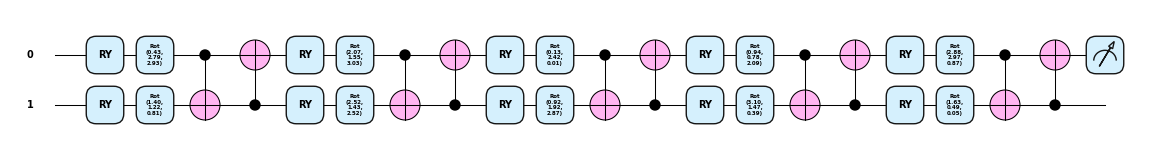

In [198]:
### Plot the model circuit nicely using matplotlib functions
### - Note that a more flexible circuit drawer can be found in utilities.py
### - Try different settings for level, e.g. 'device' and 'user'

qml.drawer.use_style('pennylane')
fig, ax = qml.draw_mpl(qnn_model, decimals=2, level='device')(test_params, test_data)
fig.set_dpi(fig.get_dpi()*0.5)
plt.show()

## Model training

### Model initialisation
<font color="CornflowerBlue">Ensure that the shape of randomly initialised parameters matches exactly the shape of the ansatz!<br>
Comment/uncomment only the required selection of the optimiser and ansatz initialisation.</font>

<font color="LightCoral">Task 2: Change the range of initialisation values.<br>
Replace <strong>high=np.pi</strong> with <strong>high=0.1</strong> then <strong>high=0.01</strong>.</font>

In [199]:
### For reproducibility
np.random.seed(seed)

### Select one of the following optimisers built into PennyLane
# opt = qml.GradientDescentOptimizer(stepsize=0.5)
# opt = qml.RMSPropOptimizer(stepsize=0.1, decay=0.7, eps=1e-08)
# opt = qml.NesterovMomentumOptimizer(stepsize=0.5)
# opt = RCDOptimizer(h=0.1)
opt = qml.AdamOptimizer(stepsize=0.5)

### Select the random initial parameters to match the ansatz shape
#init_params = np.random.uniform(high=np.pi, size=(n_layers, n_qubits), requires_grad=True)
init_params = np.random.uniform(high=np.pi, size=(n_layers, n_qubits, 3), requires_grad=True)    

### Training loop

In [200]:
### For reproducibility
np.random.seed(seed)

### Prepare training
hist_cost = []
prompt_fract = 0.1
params = copy.deepcopy(init_params)

### Training loop
start_time = time.time() 
for iter in range(epochs):
    params, cost = opt.step_and_cost(lambda p: cost_fun(p, X, y), params)
    elapsed_time = time.time()-start_time
    hist_cost.append(cost.item())
    if (prompt_fract == 0) or (iter % int(prompt_fract*epochs) == 0):
        print(f'Iter: {iter:03d} ({int(elapsed_time):03d} sec) cost={np.round(cost.numpy(), 6)}')

### Print the training summary
min_cost = np.min(hist_cost)
min_iter = np.argmin(hist_cost)
print(f'\nTraining completed: epochs={epochs}, min cost={np.round(min_cost, 6)} @ {min_iter}, time={int(elapsed_time):03d} secs\n')

Iter: 000 (001 sec) cost=[0.300039]
Iter: 005 (010 sec) cost=[0.140165]
Iter: 010 (019 sec) cost=[0.133207]
Iter: 015 (027 sec) cost=[0.108867]
Iter: 020 (035 sec) cost=[0.105256]
Iter: 025 (043 sec) cost=[0.101997]
Iter: 030 (051 sec) cost=[0.102517]
Iter: 035 (059 sec) cost=[0.100956]
Iter: 040 (067 sec) cost=[0.099614]
Iter: 045 (075 sec) cost=[0.098351]

Training completed: epochs=50, min cost=0.097974 @ 48, time=082 secs



## Plot the results
*Note that a more flexible performance and multi-curve plotters can be found in utilities.py*

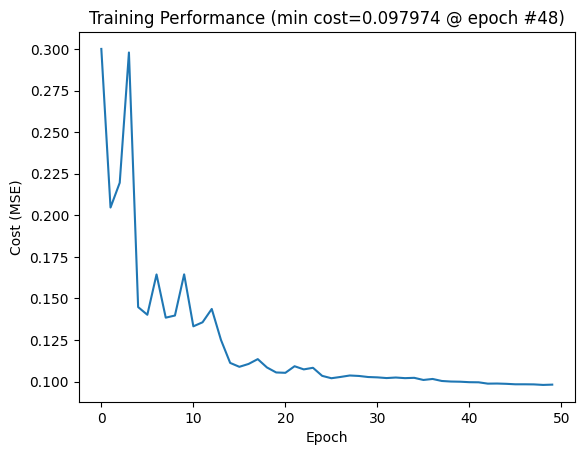

In [201]:
### Show training performance
plt.title(f'Training Performance (min cost={np.round(min_cost, 6)} @ epoch #{min_iter})')
plt.xlabel('Epoch')
plt.ylabel('Cost (MSE)')
plt.plot(hist_cost,'-')
plt.show()

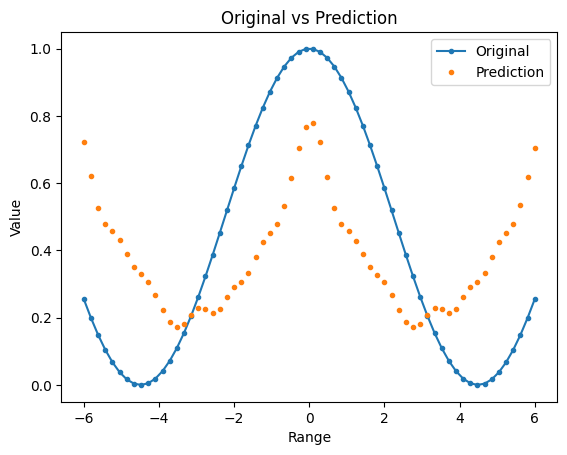

In [202]:
### Plot original vs prediction
y_pred = [qnn_model(params, x) for x in X]

plt.title('Original vs Prediction')
plt.xlabel('Range')
plt.ylabel('Value')
plt.plot(X[:,0], y, '.-', label='Original')
plt.plot(X[:,0], y_pred, '.', label='Prediction')
plt.legend(loc='best', ncol=1)
plt.show()

---

## <font color="blue">Challenge task:</font><br>Write your own optimiser (in own time)
**You can try using this Random Coordinate Descent (RCD) optimiser**<br>
*RCD is a gradient-based optimizer, so it uses the gradient of the cost function.<br>
This method updates one random parameter at the time, so it is very slow!<br>
However, think what would be the advantages of this approach!*<br/>
Ref: https://pennylane.ai/blog/2022/07/how-to-create-your-own-optimizer

In [203]:
class RCDOptimizer:
    def __init__(self, eta=0.01 , h=0.005):
        self.h = h
        self.eta = eta

    def step(self, objective_fn, theta):
        i = np.random.randint(theta.size)
        shape = theta.shape
        dt = np.eye(1,theta.size,i)
        theta = theta.reshape(-1)
        dtheta = (objective_fn((theta+dt*self.h).reshape(shape)) 
                    -objective_fn((theta-dt*self.h).reshape(shape)))/(2*self.h)
        return (theta - self.eta*dtheta*dt).reshape(shape)

    def step_and_cost(self, objective_fn, theta):
        theta = self.step(objective_fn, theta)
        return theta, objective_fn(theta)

---

## Write your observations here

- Task 1: After 50 epochs, the error drops significantly and the curve closely resembles the original. When using `lightning.qubit`, the results are more accurate, and the model runs faster because it is written in C++.

- Task 2: Setting the value to 0.01 causes the gates to start off turned off. The model has a hard time learning and performs worse.

- Task 3: Increasing the number of qubits and layers improves learning, but it takes longer to run and requires more epochs.

- Task 4: The error remains very high, so the model does not learn; with only 1 qubit and 1 layer, it lacks expressiveness. A circuit with a single rotation generates only one harmonic wave, which is not sufficient to predict our original curve.

- Task 5: When the RX rotates, it does so horizontally, causing the circuit’s Z-axis measurement to interpret it as a plane; this is why the detector fails and the predicted curve does not match.

- Task 6: With entanglement, the model has greater expressiveness since it has 3 angles, allowing for very precise tuning but with three times as many parameters, causing each epoch to take a little longer.

- Task 7: The circuit always oscillates between -1 and +1, but Dataset 2 is offset and also oscillates faster, ranging from 0 to +1, which is why it fails.

- Challenge: Data Re-uploading involves re-inputting the same number into each layer for the circuit to use, facilitating the generation of waves and various frequencies, and enabling the model to learn the data from Dataset 2.

- Reflection: A quantum machine learning model is like a Fourier series; it’s not about doing just anything to make the model learn, but rather depends on how we entangle the qubits and rotate the data.

## Modifications (do not remove)
Under the [GPL-3.0](https://www.gnu.org/licenses/gpl-3.0.txt) license, if you perform any changes to this notebook, please list them here, adding a note with your name, contact details, date and changes to the code.

- [Jacob Cybulski](http://jacobcybulski.com) (2025, 1 April): The author of this notebook added this section to record all code changes
- [Jacob Cybulski](http://jacobcybulski.com) (2026, 9 April): Now also compatible with...<br>
  pennylane                 0.45.0<br>
  pennylane_lightning       0.45.0<br>
  torch                     2.11.0+cpu<br>
  torchaudio                2.11.0<br>
  torchvision               0.26.0+cpu<br>

## Software (Linux)

In [204]:
import os
os.system('pip list | grep -e pennylane -e torch');